In [6]:
!pip install pymoo

Decisao Recomendada (Pesos 30% Custo / 70% Performance):
-> Configuracao: 76.6 GB RAM | 2755 IOPS
-> Resultado:    US$ 56.52/h | Tempo de Query: 8.06 ms


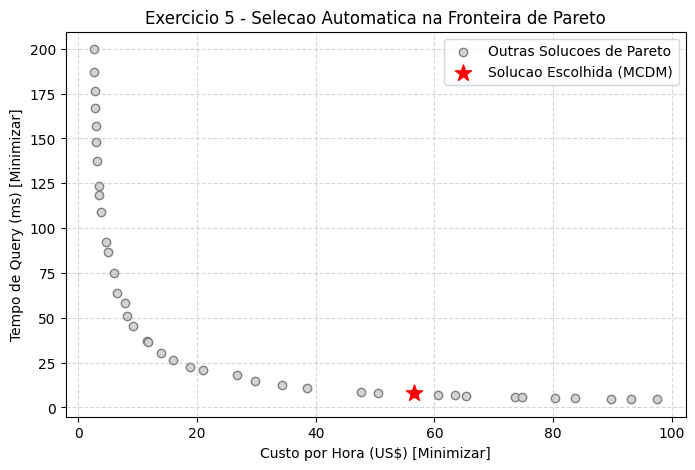

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.mcdm.pseudo_weights import PseudoWeights

class CloudDatabaseProblem(ElementwiseProblem):
    def __init__(self):
        # x1: RAM (GB), x2: IOPS Disco
        super().__init__(n_var=2, n_obj=2, xl=np.array([4.0, 100.0]), xu=np.array([128.0, 5000.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        ram, iops = x[0], x[1]
        f1_custo_hora = (ram * 0.45) + (iops * 0.008)
        f2_tempo_query = (200.0 / ram) + (15000.0 / iops)
        out["F"] = [f1_custo_hora, f2_tempo_query]

res5 = minimize(CloudDatabaseProblem(), NSGA2(pop_size=40), ('n_gen', 50), seed=42, verbose=False)

# Definindo pesos de negocio: 30% Custo, 70% Velocidade da Query
pesos = np.array([0.30, 0.70])
indice_escolhido = PseudoWeights(pesos).do(res5.F)

melhor_x = res5.X[indice_escolhido]
melhor_f = res5.F[indice_escolhido]

print("Decisao Recomendada (Pesos 30% Custo / 70% Performance):")
print(f"-> Configuracao: {melhor_x[0]:.1f} GB RAM | {melhor_x[1]:.0f} IOPS")
print(f"-> Resultado:    US$ {melhor_f[0]:.2f}/h | Tempo de Query: {melhor_f[1]:.2f} ms")

plt.figure(figsize=(8, 5))
plt.scatter(res5.F[:, 0], res5.F[:, 1], color='lightgray', edgecolor='gray', label='Outras Solucoes de Pareto')
plt.scatter(melhor_f[0], melhor_f[1], color='red', s=150, marker='*', label='Solucao Escolhida (MCDM)')
plt.title("Exercicio 5 - Selecao Automatica na Fronteira de Pareto")
plt.xlabel("Custo por Hora (US$) [Minimizar]")
plt.ylabel("Tempo de Query (ms) [Minimizar]")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()